# E5: CRNN | 64 Mel bins | không SpecAugment
Nhánh GitHub: `08-E5-crnn-mel64`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [1]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [2]:
EXP_ID = "E5"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'crnn', 'n_mels': 64, 'specaug': False}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [3]:
lr = search_lr(EXP_ID)

train:   0%|          | 0/40 [00:00<?, ?it/s]

E5 {'LR': 0.0003, 'EPOCHS': 40} -> 0.7654


train:   0%|          | 0/40 [00:00<?, ?it/s]

E5 {'LR': 0.001, 'EPOCHS': 40} -> 0.7685


,LR,EPOCHS,val_macro_f1,best_epoch
1,0.0010,40,0.768515,32
0,0.0003,40,0.765354,32


E5: learning rate được chọn = 0.001


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [4]:
runs, rob = run_exp(EXP_ID, lr)

E5 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E5 | fold 1] acc 0.7500 | macro-F1 0.7378 | lr 0.001 | epoch tốt nhất 71 | 102s


E5 | fold 2:   0%|          | 0/80 [00:00<?, ?it/s]

[E5 | fold 2] acc 0.7750 | macro-F1 0.7672 | lr 0.001 | epoch tốt nhất 55 | 103s


E5 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E5 | fold 3] acc 0.7425 | macro-F1 0.7324 | lr 0.001 | epoch tốt nhất 47 | 103s


E5 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E5 | fold 4] acc 0.7825 | macro-F1 0.7756 | lr 0.001 | epoch tốt nhất 49 | 103s


E5 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E5 | fold 5] acc 0.7325 | macro-F1 0.7167 | lr 0.001 | epoch tốt nhất 73 | 103s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.7500,0.7378,0.001,71,0.7691,102.3700
1,2,0.7750,0.7672,0.001,55,0.8062,102.5095
2,3,0.7425,0.7324,0.001,47,0.7961,102.7155
3,4,0.7825,0.7756,0.001,49,0.6980,102.9211
4,5,0.7325,0.7167,0.001,73,0.7827,102.6057


E5: Accuracy 75.65 ± 2.14 | Macro-F1 74.59 ± 2.47 | 2,071,762 tham số


,acc,macro_f1
condition,,
Sạch,75.65,74.59
20 dB,60.15,59.92
10 dB,34.50,35.04
0 dB,8.40,7.23


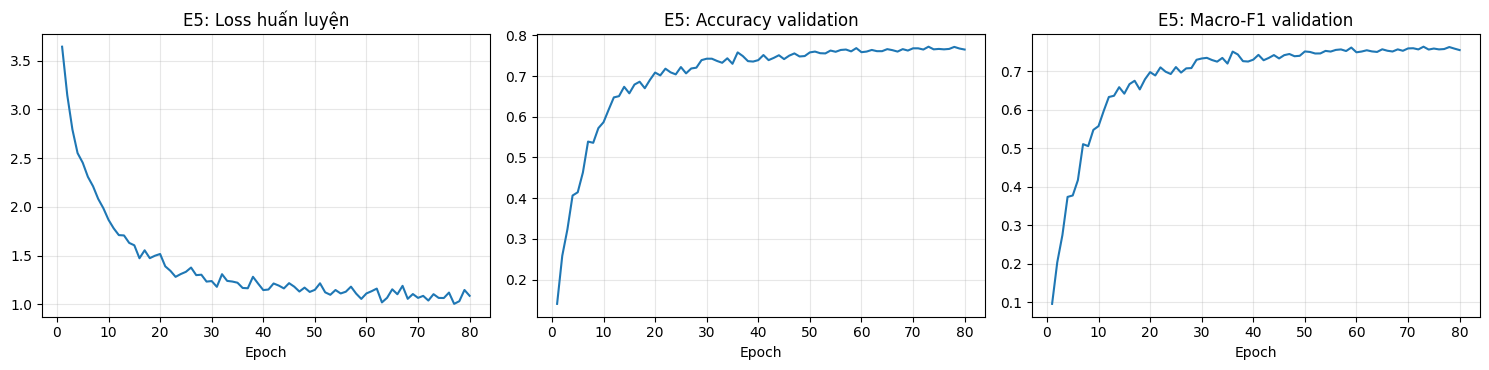

In [5]:
show_exp(EXP_ID)